# Crystal graphs

A crystal graph has one node per atom of the unit cell and one directed edge j → i for every periodic image of atom j within the cutoff radius r_c of atom i. Everything a crystal graph network sees about geometry comes from this neighbor list, so it is checked here against results that do not use the same code: exact lattice sums for the coordination shells, pymatgen's neighbor search, and the symmetries the graph must have.

| File | Contents |
|---|---|
| `materials_ml_primer/graphs.py` | neighbor search, coordination shells, graph assembly, Gaussian distance features, exact lattice sums |
| `tests/test_graphs.py` | pytest suite |
| `crystal_graphs.ipynb` | this notebook |
| `figures/` | figures written by this notebook |

Run from this folder after installing the package as described in [../../README.md](../../README.md).

In [1]:
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from pymatgen.core import Lattice, Structure

from materials_ml_primer import graphs as cg

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})
KINDS = ["sc", "bcc", "fcc", "hcp", "diamond", "rocksalt"]
summary = []   # rows of the summary table: (quantity, this run, check, check from)

## Automated tests

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "--color=no",
                    "-p", "no:cacheprovider", "../../tests/test_graphs.py"],
                   capture_output=True, text=True)
print(r.stdout[-6000:])

============================= test session starts =============================
collecting ... collected 55 items

..\..\tests\test_graphs.py::test_plane_spacings_cubic PASSED             [  1%]
..\..\tests\test_graphs.py::test_plane_spacings_hexagonal PASSED         [  3%]
..\..\tests\test_graphs.py::test_plane_spacings_equal_volume_over_area[0] PASSED [  5%]
..\..\tests\test_graphs.py::test_plane_spacings_equal_volume_over_area[1] PASSED [  7%]
..\..\tests\test_graphs.py::test_plane_spacings_equal_volume_over_area[2] PASSED [  9%]
..\..\tests\test_graphs.py::test_image_bounds_are_enough[0] PASSED       [ 10%]
..\..\tests\test_graphs.py::test_image_bounds_are_enough[1] PASSED       [ 12%]
..\..\tests\test_graphs.py::test_image_bounds_are_enough[2] PASSED       [ 14%]
..\..\tests\test_graphs.py::test_image_bounds_are_enough[3] PASSED       [ 16%]
..\..\tests\test_graphs.py::test_reference_shells_match_textbook[sc] PASSED [ 18%]
..\..\tests\test_graphs.py::test_reference_shells_match_te

## 1. How many periodic images to search

With fractional coordinates wrapped into [0, 1), the difference Δf_i of two atoms lies in (−1, 1). The component of a displacement (Δf + n)·L along the unit normal of the lattice planes spanned by the other two vectors is (Δf_i + n_i) d_i, where d_i = 1/|b_i| = V/|a_j × a_k| is the plane spacing. A neighbor within r_c therefore needs |n_i| < r_c/d_i + 1, so

$$|n_i| \le N_i = \lceil r_c / d_i \rceil .$$

The bound depends on the plane spacings, not on the lengths of the lattice vectors. A cell with long, nearly parallel vectors has small plane spacings and needs many images even when its vectors are long. To show this, the simple cubic lattice (a = 1) is written with the unimodular cell rows (1, 0, 0), (5, 1, 0), (3, 4, 1): the same lattice, so the same neighbors, but a strongly skewed cell.

In [3]:
skew = np.array([[1, 0, 0], [5, 1, 0], [3, 4, 1]], dtype=float)
print("skewed cell: |a_i| =", np.round(np.linalg.norm(skew, axis=1), 4),
      " plane spacings d_i =", np.round(cg.plane_spacings(skew), 4))
rc = 2.5
bounds = cg.image_bounds(skew, rc)
print(f"r_c = {rc}: image bounds N_i = {bounds}")

radii, counts, _ = cg.reference_shells("sc", 12)
n_exact = int(counts[radii <= rc].sum())
print(f"neighbors of an sc site within {rc} a (lattice sum): {n_exact}")

found = []
for b in range(1, bounds.max() + 2):
    c, j, n, d = cg.neighbor_list(skew, [[0.3, 0.6, 0.1]], rc, bounds=[b, b, b])
    found.append(len(d))
for b in (1, 2, 5, 10, 20, 30, 40, bounds.max()):
    print(f"  search |n_i| <= {b:2d} in every direction: {found[b - 1]:3d} neighbors")
first_complete = 1 + next(k for k, f in enumerate(found) if f == n_exact)
print(f"  first uniform range that finds all {n_exact}: |n_i| <= {first_complete}")
c, j, n, d = cg.neighbor_list(skew, [[0.3, 0.6, 0.1]], rc)
print(f"  automatic bounds {bounds}: {len(d)} neighbors")
summary.append(("skewed sc cell, neighbors within 2.5 a", f"{len(d)}", f"{n_exact}", "lattice sum"))
summary.append(("same, searching only |n_i| <= 1", f"{found[0]}", f"{n_exact}", "lattice sum"))

skewed cell: |a_i| = [1.    5.099 5.099]  plane spacings d_i = [0.0563 0.2425 1.    ]
r_c = 2.5: image bounds N_i = [45 11  3]
neighbors of an sc site within 2.5 a (lattice sum): 80


  search |n_i| <=  1 in every direction:   2 neighbors
  search |n_i| <=  2 in every direction:   4 neighbors
  search |n_i| <=  5 in every direction:  10 neighbors
  search |n_i| <= 10 in every direction:  26 neighbors
  search |n_i| <= 20 in every direction:  48 neighbors
  search |n_i| <= 30 in every direction:  68 neighbors
  search |n_i| <= 40 in every direction:  80 neighbors
  search |n_i| <= 45 in every direction:  80 neighbors
  first uniform range that finds all 80: |n_i| <= 40
  automatic bounds [45 11  3]: 80 neighbors


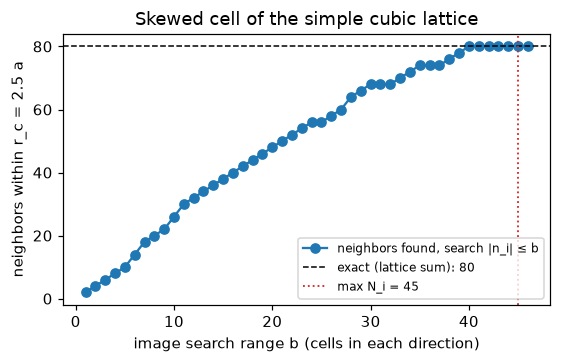

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
b_axis = np.arange(1, len(found) + 1)
ax.plot(b_axis, found, "o-", label="neighbors found, search |n_i| ≤ b")
ax.axhline(n_exact, color="k", ls="--", lw=1, label=f"exact (lattice sum): {n_exact}")
ax.axvline(bounds.max(), color="C3", ls=":", lw=1.2, label=f"max N_i = {bounds.max()}")
ax.set_xlabel("image search range b (cells in each direction)")
ax.set_ylabel("neighbors within r_c = 2.5 a")
ax.set_title("Skewed cell of the simple cubic lattice")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figures/skewed_cell.png")
plt.show()

## 2. Coordination shells against exact lattice sums

`reference_shells` counts lattice vectors by squared length in a frame where they have integer coordinates (fcc: integer vectors with even sum in units of a/2; bcc: all even or all odd; diamond: two interpenetrating fcc lattices in units of a/4; rock salt: a simple cubic lattice of spacing a/2 with alternating species; ideal hcp: the hexagonal quadratic form n₁² − n₁n₂ + n₂² + (c/a)² n₃² in exact fractions). It never builds a lattice matrix or searches images, so it is independent of `neighbor_list`, which is run here on the primitive cells.

In [5]:
a = 3.6
print(f"{'kind':9s} {'atoms':>5s} {'shells':>6s}  counts (first 8 shells)                  max |Δr|/r   counts equal")
for kind in KINDS:
    radii, counts, other = cg.reference_shells(kind, 9)
    lat, frac, _ = cg.primitive_cell(kind, a=a)
    cutoff = a * 0.5 * (radii[-2] + radii[-1])
    c, j, n, d = cg.neighbor_list(lat, frac, cutoff)
    worst, equal = 0.0, True
    for i in range(len(frac)):
        r_i, k_i = cg.shells(d[c == i])
        worst = max(worst, np.max(np.abs(r_i / (a * radii[:8]) - 1)))
        equal &= np.array_equal(k_i, counts[:8])
    print(f"{kind:9s} {len(frac):5d} {8:6d}  {str(counts[:8].tolist()):40s} {worst:10.1e}   {equal}")
    summary.append((f"{kind}: first 8 shell counts", str(k_i.tolist()), str(counts[:8].tolist()), "lattice sum"))
    summary.append((f"{kind}: max relative error of shell radii", f"{worst:.1e}", "0", "lattice sum"))

kind      atoms shells  counts (first 8 shells)                  max |Δr|/r   counts equal
sc            1      8  [6, 12, 8, 6, 24, 24, 12, 30]               3.3e-16   True
bcc           1      8  [8, 6, 12, 24, 8, 6, 24, 24]                2.2e-16   True
fcc           1      8  [12, 6, 24, 12, 24, 8, 48, 6]               3.3e-16   True
hcp           2      8  [12, 6, 2, 18, 12, 6, 12, 12]               4.4e-16   True
diamond       2      8  [4, 12, 12, 6, 12, 24, 16, 12]              3.3e-16   True
rocksalt      2      8  [6, 12, 8, 6, 24, 24, 12, 30]               3.3e-16   True


fcc and ideal hcp are both close-packed and agree in the first two shells (12 at d, 6 at √2 d); they first differ in the third shell (fcc: 24 at √3 d; hcp: 2 at √(8/3) d, then 18 at √3 d). In rock salt the species alternate between shells: the 6, 8 and 24 neighbors of shells 1, 3 and 5 are the other species.

At large r every cumulative count N(r) must approach the number of atoms in a sphere, (4π/3) ρ r³, with ρ the number density.

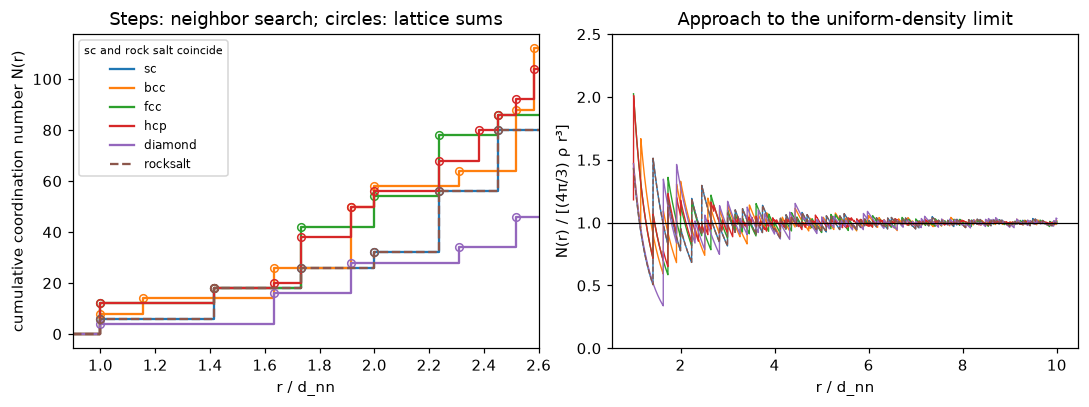

In [6]:
rc_over_dnn, r_left = 10.0, 2.6
styles = {"sc": "-", "bcc": "-", "fcc": "-", "hcp": "-", "diamond": "-", "rocksalt": "--"}
grid = np.linspace(1.0, rc_over_dnn, 4000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for kind in KINDS:
    lat, frac, _ = cg.primitive_cell(kind, a=1.0)
    c, j, n, d = cg.neighbor_list(lat, frac, 1.0)            # nearest-neighbor distance
    dnn = d.min()
    c, j, n, d = cg.neighbor_list(lat, frac, rc_over_dnn * dnn)
    d0 = np.sort(d[c == 0]) / dnn
    r_sh, k_sh = cg.shells(d0, tol=1e-9)
    rho = len(frac) / abs(np.linalg.det(lat)) * dnn ** 3   # atoms per d_nn^3
    radii, counts, _ = cg.reference_shells(kind, 12)
    x = np.r_[0.9, r_sh[r_sh <= r_left], r_left]
    y = np.r_[0, np.cumsum(k_sh)[r_sh <= r_left], np.cumsum(k_sh)[r_sh <= r_left][-1]]
    l, = axes[0].step(x, y, where="post", ls=styles[kind], label=kind)
    keep = radii / radii[0] <= r_left
    axes[0].plot(radii[keep] / radii[0], np.cumsum(counts)[keep], "o", mfc="none",
                 color=l.get_color(), ms=5)
    n_grid = np.searchsorted(d0, grid, side="right")         # N(r) on a fine grid
    axes[1].plot(grid, n_grid / (4 / 3 * np.pi * rho * grid ** 3), lw=0.9, ls=styles[kind],
                 color=l.get_color(), label=kind)
axes[0].set_xlim(0.9, r_left)
axes[0].set_xlabel("r / d_nn")
axes[0].set_ylabel("cumulative coordination number N(r)")
axes[0].set_title("Steps: neighbor search; circles: lattice sums")
axes[0].legend(fontsize=8, title="sc and rock salt coincide", title_fontsize=7)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_xlabel("r / d_nn")
axes[1].set_ylabel("N(r) / [(4π/3) ρ r³]")
axes[1].set_title("Approach to the uniform-density limit")
axes[1].set_ylim(0, 2.5)
fig.tight_layout()
fig.savefig("figures/coordination_shells.png")
plt.show()

## 3. Edge-for-edge agreement with pymatgen

`Structure.get_neighbor_list` (pymatgen) returns the same kind of triples (center, neighbor, image offset, distance). The comparison uses random triclinic cells with coordinates outside [0, 1), so that the conversion of image offsets back to the input coordinates is exercised, and a few real structures.

In [7]:
def wurtzite_zno():
    a, c, u = 3.25, 5.21, 0.382
    lat = Lattice.hexagonal(a, c)
    return Structure(lat, ["Zn", "Zn", "O", "O"],
                     [[1/3, 2/3, 0], [2/3, 1/3, 0.5], [1/3, 2/3, u], [2/3, 1/3, 0.5 + u]])

structures = {
    "Cu (fcc, conventional)": Structure(Lattice.cubic(3.615), ["Cu"] * 4,
                                        [[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]]),
    "Mg (hcp, c/a = 1.624)": Structure(Lattice.hexagonal(3.209, 5.211), ["Mg", "Mg"],
                                       [[1/3, 2/3, 0.25], [2/3, 1/3, 0.75]]),
    "ZnO (wurtzite)": wurtzite_zno(),
    "SrTiO3 (perovskite)": Structure(Lattice.cubic(3.905), ["Sr", "Ti", "O", "O", "O"],
                                     [[0, 0, 0], [0.5, 0.5, 0.5], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]]),
}
rng = np.random.default_rng(7)
for k in range(4):
    lat = 3.0 * np.eye(3) + rng.uniform(-1, 1, (3, 3))
    frac = rng.uniform(-0.5, 1.5, (4 + 2 * k, 3))
    structures[f"random triclinic #{k + 1}"] = Structure(Lattice(lat), ["Si"] * len(frac), frac)

cutoff = 8.0
n_edges_total, all_equal, worst = 0, True, 0.0
print(f"r_c = {cutoff} Å")
print(f"{'structure':26s} {'atoms':>5s} {'edges':>7s}  same edges  max |Δd|/d")
for name, s in structures.items():
    lat, frac, _ = cg.from_structure(s)
    c, j, n, d = cg.neighbor_list(lat, frac, cutoff)
    pc, pj, pn, pd = s.get_neighbor_list(cutoff)
    mine = {(a_, b_, *m): x for a_, b_, m, x in zip(c.tolist(), j.tolist(), n.tolist(), d)}
    theirs = {(a_, b_, *m): x for a_, b_, m, x in zip(pc.tolist(), pj.tolist(), pn.astype(int).tolist(), pd)}
    same = mine.keys() == theirs.keys()
    rel = max(abs(mine[e] / theirs[e] - 1) for e in theirs) if same else np.nan
    n_edges_total += len(d)
    all_equal &= same
    worst = max(worst, rel)
    print(f"{name:26s} {len(s):5d} {len(d):7d}  {str(same):10s}  {rel:.1e}")
summary.append((f"edges identical to pymatgen ({len(structures)} structures, {n_edges_total} edges)",
                str(all_equal), "True", "pymatgen get_neighbor_list"))
summary.append(("max relative difference of edge lengths", f"{worst:.1e}", "0", "pymatgen get_neighbor_list"))

r_c = 8.0 Å
structure                  atoms   edges  same edges  max |Δd|/d
Cu (fcc, conventional)         4     704  True        2.2e-16
Mg (hcp, c/a = 1.624)          2     172  True        3.3e-16
ZnO (wurtzite)                 4     704  True        4.4e-16
SrTiO3 (perovskite)            5     824  True        2.2e-16
random triclinic #1            4    1124  True        1.3e-15
random triclinic #2            6    3198  True        6.7e-16
random triclinic #3            8    6128  True        1.6e-15
random triclinic #4           10    6916  True        1.8e-15


In [8]:
s = structures["random triclinic #4"]
lat, frac, _ = cg.from_structure(s)
t0 = time.perf_counter(); cg.neighbor_list(lat, frac, cutoff); t_mine = time.perf_counter() - t0
t0 = time.perf_counter(); s.get_neighbor_list(cutoff); t_pmg = time.perf_counter() - t0
print(f"{len(s)} atoms, r_c = {cutoff} Å: this module {t_mine * 1e3:.1f} ms, pymatgen {t_pmg * 1e3:.1f} ms")

10 atoms, r_c = 8.0 Å: this module 2.9 ms, pymatgen 0.5 ms


The NumPy search visits every atom pair in every image cell, which is fine for verification but scales as N² per cell. pymatgen's compiled search gives the same edges and is the one to use for the tens of thousands of structures in the `cgcnn` experiment, now that the two are known to agree.

## 4. Invariances

A graph built from a crystal must not depend on how the crystal is written down. Each check below changes the description and compares the result.

In [9]:
def max_rel(x, y):
    return float(np.max(np.abs(np.asarray(x) / np.asarray(y) - 1)))

def edges(c, j, n, d):
    return {(a_, b_, *m): x for a_, b_, m, x in zip(c.tolist(), j.tolist(), n.tolist(), d)}

s = structures["ZnO (wurtzite)"]
lat, frac, _ = cg.from_structure(s)
c0, j0, n0, d0 = cg.neighbor_list(lat, frac, cutoff)

# Compare edges as sets: equal distances (ties) may be listed in a different order.
q, r_ = np.linalg.qr(np.random.default_rng(3).normal(size=(3, 3)))
rot = q * np.sign(np.diag(r_))
e0, e1 = edges(c0, j0, n0, d0), edges(*cg.neighbor_list(lat @ rot.T, frac, cutoff))
rot_edges = e0.keys() == e1.keys()
rot_err = max(abs(e1[k] / e0[k] - 1) for k in e0)

shift = np.array([0.37, -1.21, 2.05])
c2, j2, n2, d2 = cg.neighbor_list(lat, frac + shift, cutoff)
tr_err = max_rel(d2, d0)

perm = np.array([2, 0, 3, 1])
c3, j3, n3, d3 = cg.neighbor_list(lat, frac[perm], cutoff)
perm_ok = ({(perm[a_], perm[b_], *m) for a_, b_, m in zip(c3, j3, n3.tolist())}
           == {(a_, b_, *m) for a_, b_, m in zip(c0, j0, n0.tolist())})

reps = np.array([2, 2, 1])
shifts = np.array([[x, y, 0] for x in range(2) for y in range(2)])
super_frac = ((frac[None] + shifts[:, None]) / reps).reshape(-1, 3)
parent = np.tile(np.arange(len(frac)), len(shifts))
c4, j4, n4, d4 = cg.neighbor_list(lat * reps[:, None], super_frac, cutoff)
sup_err = max(max_rel(np.sort(d4[c4 == k]), np.sort(d0[c0 == parent[k]])) for k in range(len(super_frac)))

print(f"wurtzite ZnO, r_c = {cutoff} Å, {len(d0)} edges")
print(f"rigid rotation:   same edges {rot_edges}, max |Δd|/d = {rot_err:.1e}")
print(f"translation:      max |Δd|/d = {tr_err:.1e}")
print(f"permutation:      same edges after relabeling {perm_ok}")
print(f"2×2×1 supercell:  every atom has its parent's distances, max |Δd|/d = {sup_err:.1e}")
summary += [("rotation: max relative change of edge lengths", f"{rot_err:.1e}", "0", "invariance"),
            ("translation: max relative change", f"{tr_err:.1e}", "0", "invariance"),
            ("permutation: edges identical after relabeling", str(perm_ok), "True", "invariance"),
            ("2×2×1 supercell: max relative change per atom", f"{sup_err:.1e}", "0", "invariance")]

wurtzite ZnO, r_c = 8.0 Å, 704 edges
rigid rotation:   same edges True, max |Δd|/d = 6.7e-16
translation:      max |Δd|/d = 2.2e-16
permutation:      same edges after relabeling True
2×2×1 supercell:  every atom has its parent's distances, max |Δd|/d = 4.4e-16


## 5. Distance features

CGCNN does not feed raw distances to the network. Each edge length d is expanded in Gaussians exp(−((d − μ_k)/σ)²) with centers μ_k = 0, 0.2, …, 8 Å (41 centers) and σ = 0.2 Å. A distance then activates a few neighboring centers, which lets a linear layer respond to it smoothly.

41 centers from 0.0 to 8.0 Å; feature value at d = μ ± σ: 0.367879 (e^-1 = 0.367879)


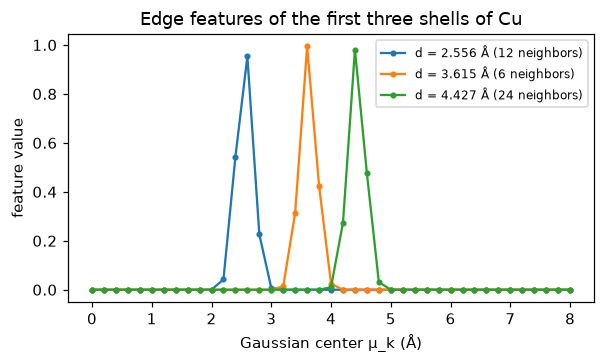

In [10]:
mu = cg.gaussian_centers()
lat, frac, _ = cg.from_structure(structures["Cu (fcc, conventional)"])
c, j, n, d = cg.neighbor_list(lat, frac, 4.5)
r_shell, k_shell = cg.shells(d[c == 0])
feats = cg.gaussian_expansion(r_shell, mu, 0.2)
print(f"{len(mu)} centers from {mu[0]} to {mu[-1]} Å; feature value at d = μ ± σ: {cg.gaussian_expansion([2.2], [2.0], 0.2)[0, 0]:.6f} (e^-1 = {np.exp(-1):.6f})")
summary.append(("Gaussian feature at d = μ ± σ", f"{cg.gaussian_expansion([2.2], [2.0], 0.2)[0, 0]:.15f}", f"{np.exp(-1):.15f}", "e^-1"))

fig, ax = plt.subplots(figsize=(5.6, 3.4))
for r_, k_, f_ in zip(r_shell, k_shell, feats):
    ax.plot(mu, f_, "o-", ms=3, label=f"d = {r_:.3f} Å ({k_} neighbors)")
ax.set_xlabel("Gaussian center μ_k (Å)")
ax.set_ylabel("feature value")
ax.set_title("Edge features of the first three shells of Cu")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/gaussian_features.png")
plt.show()

## 6. Capping the number of neighbors

CGCNN keeps only the 12 nearest neighbors within 8 Å of each atom. With a cap, the graph is no longer symmetric (j can be among the 12 nearest of i without i being among the 12 nearest of j), and the choice is ambiguous when several neighbors are equally far at the cap. In bcc Fe the first two shells hold 8 + 6 = 14 atoms, so a cap of 12 keeps 4 of 6 equidistant second neighbors. Which 4 is decided by round-off and sort order; the kept *distances* are always 8 × d₁ + 4 × d₂.

In [11]:
lat, frac, _ = cg.primitive_cell("bcc", a=2.87)
kept = []
for seed in range(6):
    q, r_ = np.linalg.qr(np.random.default_rng(seed).normal(size=(3, 3)))
    rot = q * np.sign(np.diag(r_))
    g = cg.build_graph(lat @ rot.T, frac, 8.0, max_neighbors=12)
    second = g["images"][np.isclose(g["distances"], 2.87)]
    kept.append(frozenset(map(tuple, second.tolist())))
    dist_ok = np.allclose(np.sort(g["distances"]), np.r_[[2.87 * 3 ** .5 / 2] * 8, [2.87] * 4])
    print(f"rotation {seed}: kept second neighbors at images {sorted(second.tolist())}; distances 8×d1 + 4×d2: {dist_ok}")
print(f"different choices of the 4 second neighbors among 6 rotations: {len(set(kept))}")

rotation 0: kept second neighbors at images [[-1, -1, 0], [0, -1, -1], [0, 1, 1], [1, 1, 0]]; distances 8×d1 + 4×d2: True
rotation 1: kept second neighbors at images [[-1, -1, 0], [0, -1, -1], [0, 1, 1], [1, 1, 0]]; distances 8×d1 + 4×d2: True
rotation 2: kept second neighbors at images [[-1, -1, 0], [-1, 0, -1], [0, -1, -1], [0, 1, 1]]; distances 8×d1 + 4×d2: True
rotation 3: kept second neighbors at images [[-1, -1, 0], [-1, 0, -1], [1, 0, 1], [1, 1, 0]]; distances 8×d1 + 4×d2: True
rotation 4: kept second neighbors at images [[-1, -1, 0], [-1, 0, -1], [0, -1, -1], [1, 0, 1]]; distances 8×d1 + 4×d2: True
rotation 5: kept second neighbors at images [[-1, -1, 0], [-1, 0, -1], [1, 0, 1], [1, 1, 0]]; distances 8×d1 + 4×d2: True
different choices of the 4 second neighbors among 6 rotations: 4


For a model that uses only distances and the species of the neighbors, as CGCNN does, the ambiguity is harmless here because the tied atoms are the same element at the same distance. A model that also uses edge directions would see a different graph for each choice. The `cgcnn` experiment follows the published CGCNN setup; the tie is worth keeping in mind when comparing graph builders.

## Summary

Every value next to an independent check.

In [12]:
def rel_diff(a_, b_):
    try:
        x, y = float(a_), float(b_)
    except ValueError:
        return "–" if a_ == b_ else "differs"
    if y == 0:
        return f"{abs(x):.1e} (abs)"
    return f"{abs(x / y - 1):.1e}"

w = max(len(r[0]) for r in summary)
print(f"{'quantity':{w}s}  {'this run':>30s}  {'check':>30s}  {'check from':28s}  rel. diff")
for q_, a_, b_, src in summary:
    print(f"{q_:{w}s}  {a_:>30s}  {b_:>30s}  {src:28s}  {rel_diff(a_, b_)}")

quantity                                                                       this run                           check  check from                    rel. diff
skewed sc cell, neighbors within 2.5 a                                               80                              80  lattice sum                   0.0e+00
same, searching only |n_i| <= 1                                                       2                              80  lattice sum                   9.7e-01
sc: first 8 shell counts                                  [6, 12, 8, 6, 24, 24, 12, 30]   [6, 12, 8, 6, 24, 24, 12, 30]  lattice sum                   –
sc: max relative error of shell radii                                           3.3e-16                               0  lattice sum                   3.3e-16 (abs)
bcc: first 8 shell counts                                  [8, 6, 12, 24, 8, 6, 24, 24]    [8, 6, 12, 24, 8, 6, 24, 24]  lattice sum                   –
bcc: max relative error of shell radii            